In [1]:
%pip install transformers torch sentence-transformers sentencepiece spacy

# 07 Review intelligence (stage 4): what do customers complain about, in any language?
Built on Olist's Portuguese reviews, then tested on Danish Trustpilot reviews (ScandiSent).

## Step 1. Sentiment on a sample, checked against the stars
Model: Cardiff NLP XLM-T (twitter-xlm-roberta-base-sentiment), trained for sentiment in 8 languages including Portuguese. Labels: negative, neutral, positive.
The star rating is the answer key: a good model should call most 1-star comments negative and most 5-star comments positive.

In [2]:
import time
import numpy as np
import pandas as pd
from transformers import pipeline

reviews = pd.read_parquet(r"..\data\processed\reviews_clean.parquet")
comments = reviews.dropna(subset=['review_comment_message']).copy()
print("Reviews with a comment:", len(comments))

sample = comments.sample(2000, random_state=42)

clf = pipeline('sentiment-analysis',
               model='cardiffnlp/twitter-xlm-roberta-base-sentiment',
               truncation=True, max_length=256)

start = time.time()
out = clf(sample['review_comment_message'].tolist(), batch_size=32)
print(f"Time: {time.time() - start:.0f} seconds for 2,000 comments")

sample['sentiment'] = [o['label'].lower() for o in out]
pd.crosstab(sample['review_score'], sample['sentiment'], normalize='index').mul(100).round(0)

Reviews with a comment: 40775


Time: 90 seconds for 2,000 comments


sentiment,negative,neutral,positive
review_score,,,
1,65.0,34.0,2.0
2,58.0,36.0,7.0
3,45.0,33.0,23.0
4,14.0,30.0,56.0
5,3.0,14.0,83.0


**Result.** 2,000 comments in 90 seconds (full run about 30 minutes on a laptop CPU).
The model agrees with the stars at the extremes: 83% of 5-star comments are positive, 65% of 1-star comments negative. Clear contradictions are rare (2 to 3%).
Weak spot: 34% of 1-star comments are labelled neutral. Hypothesis: complaints are often written as facts ("the product did not arrive") without emotional words, which a model trained on tweets reads as neutral.

In [3]:
from sklearn.metrics import accuracy_score, f1_score

def stars_to_label(s):
    return 'negative' if s <= 2 else ('neutral' if s == 3 else 'positive')

sample['star_label'] = sample['review_score'].apply(stars_to_label)
print("Accuracy:", round(accuracy_score(sample['star_label'], sample['sentiment']) * 100, 1), "%")
print("Macro F1:", round(f1_score(sample['star_label'], sample['sentiment'], average='macro'), 3))

pd.set_option('display.max_colwidth', 200)
sample.loc[(sample['review_score'] == 1) & (sample['sentiment'] == 'neutral'),
           'review_comment_message'].head(10)

Accuracy: 69.0 %
Macro F1: 0.564


74508                                                                                                                                  A quantidade entregue não foi a comprada.\r\nRecebi apenas 1 unidade.
89039                                                                                                                                                                             Ainda não recebi o produto
60440                                                                                                         Fiz a compra de 2 cartuchos de impressora, que estou precisando muito, e até agora não recebi.
63753                                                                                                                                                                             Não recebi o produto aínda
65344                                                                                                                                  Aguardo a devolução do produto pois o mesmo v

**Baseline (stars → labels: 1 to 2 negative, 3 neutral, 4 to 5 positive):** accuracy 69.0%, macro F1 0.564. This is the score the fine-tuned model in stage 5 must beat.

**Why 1-star comments read as neutral:** a sample of 10 confirms it. Every one is a clear complaint written as a plain fact ("I still haven't received the product"; "only 1 unit of the 6 I bought was delivered"). A model trained on tweets looks for emotional language and misses factual complaints, which are typical in e-commerce.
Half of the sample describes incomplete orders, matching the stage 3 finding on multi-item orders.
Note: shop names in the data are anonymised with invented names (for example "Lannister").

## Step 2. Sentiment on all comments
All 40,775 comments, in chunks of 2,000 with progress printed. Results saved to data/processed/reviews_sentiment.parquet so the run is needed only once.

In [4]:
texts = comments['review_comment_message'].tolist()
results = []
start = time.time()

for i in range(0, len(texts), 2000):
    results.extend(clf(texts[i:i + 2000], batch_size=32))
    print(f"{min(i + 2000, len(texts)):,} of {len(texts):,} done | {time.time() - start:.0f} s")

comments['sentiment'] = [r['label'].lower() for r in results]
comments['sentiment_score'] = [r['score'] for r in results]
comments['star_label'] = comments['review_score'].apply(stars_to_label)

comments.to_parquet(r"..\data\processed\reviews_sentiment.parquet")
print("Saved.")

2,000 of 40,775 done | 94 s
4,000 of 40,775 done | 188 s
6,000 of 40,775 done | 281 s
8,000 of 40,775 done | 373 s
10,000 of 40,775 done | 465 s
12,000 of 40,775 done | 559 s
14,000 of 40,775 done | 652 s
16,000 of 40,775 done | 745 s
18,000 of 40,775 done | 840 s
20,000 of 40,775 done | 927 s
22,000 of 40,775 done | 1008 s
24,000 of 40,775 done | 1091 s
26,000 of 40,775 done | 1175 s
28,000 of 40,775 done | 1258 s
30,000 of 40,775 done | 1341 s
32,000 of 40,775 done | 1423 s
34,000 of 40,775 done | 1507 s
36,000 of 40,775 done | 1591 s
38,000 of 40,775 done | 1674 s
40,000 of 40,775 done | 1756 s
40,775 of 40,775 done | 1787 s
Saved.


## Step 2b. Full results and hidden complaints
Check the sample results on all 40,775 comments. Then find 4 to 5 star reviews whose text the model calls negative with at least 80% confidence: problems a star-rating dashboard would never show.

In [6]:
print("Accuracy:", round(accuracy_score(comments['star_label'], comments['sentiment']) * 100, 1), "%")
print("Macro F1:", round(f1_score(comments['star_label'], comments['sentiment'], average='macro'), 3), "\n")
print(pd.crosstab(comments['review_score'], comments['sentiment'], normalize='index').mul(100).round(1), "\n")

hidden = comments[(comments['review_score'] >= 4)
                  & (comments['sentiment'] == 'negative')
                  & (comments['sentiment_score'] >= 0.8)]
print("4 to 5 star reviews with confidently negative text:", len(hidden),
      f"({len(hidden) / (comments['review_score'] >= 4).sum() * 100:.1f}% of 4 to 5 star comments)")
hidden['review_comment_message'].head(10)

Accuracy: 69.9 %
Macro F1: 0.571 

sentiment     negative  neutral  positive
review_score                             
1                 64.0     34.7       1.4
2                 56.5     38.0       5.5
3                 40.8     37.7      21.5
4                 15.3     25.9      58.8
5                  3.6     13.8      82.7 

4 to 5 star reviews with confidently negative text: 448 (1.7% of 4 to 5 star comments)


10        Sei que esse não e o canal ideal, estou ha dias tentando realizar esse cancelamento e não estou conseguindo.\r\nRecebi o produto, porém minha filha ganhou o mesmo produto do pai. Preciso cancelar.
48     O produto chegou na minha cidade mas não na minha residência pois os correios são um órgão cheio de falhas com isso não levou até a minha casa tive o transtorno de ir buscar o objeto na sede mas p...
149                                                                                            É um pouco difícil de mexer pois é inglês o papel de explicação e não é original também demora muito esquentar 
177                                                                                     estranhei porque comprei varios produtos e recebi em varios dias, todos picados, acho que devíamos ser informado disso
381                                                      A UNICA RECLAMAÇÃO COM baratheon É DE QUE CADA PRODUTO É COBRADO FRETE INDIVIDUAL, COMPREI 4 PRODUTO NA MESMA COMPR

**Full results.** Accuracy 69.9%, macro F1 0.571 on all 40,775 comments, matching the sample. Baseline for stage 5: macro F1 0.571.

**Hidden complaints.** 448 reviews with 4 to 5 stars (1.7%) have text the model calls negative with at least 80% confidence. In a sample of 10, 9 describe real problems: cancellation, last-mile delivery, defects, damage in transit, shipping costs, and split deliveries without warning. One was a model mistake (a positive review in capital letters).
Multi-item problems appear again (split deliveries; shipping charged per item), a third independent signal after the stage 3 model and the 1-star comments.
These problems are invisible in a star-rating dashboard; the text catches them.

## Step 3. Complaint themes: embeddings + k-means
Each 1 to 2 star comment is turned into an embedding (a list of numbers capturing its meaning) with paraphrase-multilingual-MiniLM-L12-v2, a small multilingual model. Similar complaints get similar numbers; k-means groups them into themes.
Text clusters overlap, so silhouette scores are low; k is chosen mainly by whether the themes are readable.

In [7]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PROC = r"..\data\processed"

bad = comments[comments['review_score'] <= 2].copy()
print("Bad-review comments:", len(bad))

embedder = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
start = time.time()
emb = embedder.encode(bad['review_comment_message'].tolist(), batch_size=64,
                      show_progress_bar=True, normalize_embeddings=True)
print(emb.shape, f"| {time.time() - start:.0f} s")

np.save(PROC + r"\bad_embeddings.npy", emb)
bad.to_parquet(PROC + r"\bad_comments.parquet")

for k in range(4, 13, 2):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(emb)
    print(k, round(silhouette_score(emb, km.labels_, sample_size=5000, random_state=42), 3))

Bad-review comments: 10839


(10839, 384) | 99 s
4 0.056
6 0.038
8 0.038
10 0.034
12 0.043


**Choosing k.** Silhouette 0.034 to 0.056 for k = 4 to 12: complaint texts overlap heavily, as expected (one comment often mentions several problems). No k stands out, so k = 8 is chosen as detailed enough to separate problems that need different fixes, then checked by reading each theme.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from spacy.lang.pt.stop_words import STOP_WORDS

K = 8
km8 = KMeans(n_clusters=K, n_init=10, random_state=42).fit(emb)
bad['theme'] = km8.labels_

tfidf = TfidfVectorizer(stop_words=list(STOP_WORDS), min_df=5, ngram_range=(1, 2))
tf = tfidf.fit_transform(bad['review_comment_message'].str.lower())
terms = np.array(tfidf.get_feature_names_out())

dist = km8.transform(emb)
for c in range(K):
    mask = (bad['theme'] == c).values
    top = terms[np.asarray(tf[mask].mean(axis=0)).ravel().argsort()[::-1][:8]]
    print(f"\n=== Theme {c} | {mask.sum():,} comments ({mask.mean() * 100:.1f}%) ===")
    print("Top words:", ", ".join(top))
    for i in np.argsort(dist[:, c])[:3]:
        print("  -", bad['review_comment_message'].iloc[i][:150].replace('\r\n', ' '))


=== Theme 0 | 1,510 comments (13.9%) ===
Top words: pedido, recebi, produto, entregue, entrega, correios, contato, correio
  - Não recebi o produto, entrei com o pedido de cancelamento e estorno do valor pago! Aguardo o andamento da solicitação
  - Até esta data não recebi um posicionamento sobre a entrega do produto comprado. Apenas enviaram um email dizendo que houve problema na entrega e até a
  - O produto não entregue. Mandei mensagem sobre providências e ninguém me responde. Solicitei cancelamento e até agora sem resposta.

=== Theme 1 | 1,382 comments (12.8%) ===
Top words: comprei, recebi, veio, produtos, unidades, entregue, outro, produto
  - Eu comprei 2 lustres e so recebir 1 e consta como o meu produto foi entregue mais não foi
  - Comprei 2 unidades porém na embalagem veio apenas um. Aguardo retorno.
  - comprei duas unidades da mangueira. apenas 01 foi entregue.

=== Theme 2 | 1,390 comments (12.8%) ===
Top words: entrega, prazo, produto, dia, prazo entrega, dias, aguard

**Reading the themes.** Themes 3, 6 and 7 all say "not received" but differ in writing style (capital letters; no accents or slang): the embedding model picks up style as well as meaning. They are merged by reading.
Final themes: not delivered or late (40.6%), product quality (18.5%), lost trust in the shop (14.2%), not delivered with no answer from support (13.9%), incomplete order (12.8%).

## Step 3b. Checking themes against the order data
If the themes are real, late-order and multi-item shares should differ between them.

In [9]:
theme_names = {0: 'Not delivered + no support answer', 1: 'Incomplete order',
               2: 'Not delivered or late', 3: 'Not delivered or late',
               4: 'Lost trust in shop', 5: 'Product quality',
               6: 'Not delivered or late', 7: 'Not delivered or late'}
bad['theme_name'] = bad['theme'].map(theme_names)

orders = pd.read_parquet(PROC + r"\orders_clean.parquet")
print([c for c in orders.columns if 'late' in c or 'item' in c])

['is_late', 'n_items']


                                   complaints  not_delivered_pct  late_pct  \
theme_name                                                                   
Not delivered or late                    4402               19.2      41.1   
Product quality                          2002                1.4       4.0   
Lost trust in shop                       1543               21.2      25.3   
Not delivered + no support answer        1510               24.8      25.7   
Incomplete order                         1382                2.2       5.7   

                                   multi_item_pct  share_pct  
theme_name                                                    
Not delivered or late                        14.6       40.6  
Product quality                               9.6       18.5  
Lost trust in shop                           12.6       14.2  
Not delivered + no support answer            18.7       13.9  
Incomplete order                             68.0       12.8  


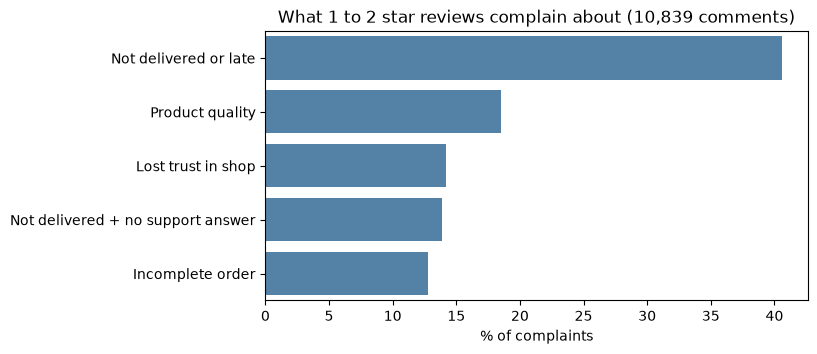

In [10]:
check = bad.merge(orders[['order_id', 'order_status', 'is_late', 'n_items']], on='order_id', how='left')
check['not_delivered'] = check['order_status'] != 'delivered'
check['multi_item'] = check['n_items'] >= 2

summary = check.groupby('theme_name').agg(
    complaints=('order_id', 'size'),
    not_delivered_pct=('not_delivered', 'mean'),
    late_pct=('is_late', lambda s: s.dropna().astype(float).mean()),
    multi_item_pct=('multi_item', 'mean'),
)
summary['share_pct'] = summary['complaints'] / summary['complaints'].sum()
pct_cols = ['not_delivered_pct', 'late_pct', 'multi_item_pct', 'share_pct']
summary[pct_cols] = summary[pct_cols] * 100
summary = summary.sort_values('complaints', ascending=False).round(1)
print(summary)

# Chart
import seaborn as sns
import matplotlib.pyplot as plt
FIG = r"..\reports\figures"

plt.figure(figsize=(7, 3.5))
sns.barplot(data=summary.reset_index(), x='share_pct', y='theme_name', color='steelblue')
plt.title('What 1 to 2 star reviews complain about (10,839 comments)')
plt.xlabel('% of complaints'); plt.ylabel('')
plt.savefig(FIG + r"\s4_complaint_themes.png", dpi=150, bbox_inches='tight')
plt.show()

**Result: themes confirmed by the order data.**
- Incomplete order: 68.0% multi-item orders, versus 10 to 19% in other themes. The text model found the stage 3 finding independently.
- Product quality: only 1.4% undelivered and 4.0% late; the parcel arrived on time, the product disappointed. The fix is product information and quality control, not logistics.
- Not delivered or late: 41.1% late, six times the 6.8% average.
- No support answer: the highest undelivered share (24.8%); customers with a failed delivery also got no reply.
- Lost trust in shop: mostly delivery failures that turned into "I won't buy here again".

In [11]:
c2 = check.merge(orders[['order_id', 'order_delivered_customer_date']], on='order_id', how='left')
on_time = c2[(c2['theme_name'] == 'Not delivered or late')
             & (c2['order_status'] == 'delivered')
             & (c2['is_late'] == False)]
before = (pd.to_datetime(on_time['review_creation_date'])
          < pd.to_datetime(on_time['order_delivered_customer_date']).dt.normalize())
print(len(on_time), "on-time delivered orders in this theme |",
      round(before.mean() * 100, 1), "% reviewed before the recorded delivery date")

1749 on-time delivered orders in this theme | 0.5 % reviewed before the recorded delivery date


**Were they reviewing too early?** No: only 0.5% of 1,749 on-time delivered orders in this theme were reviewed before the recorded delivery date. Customers complained about delivery after the system marked the order as delivered on time.
Two possible explanations: the parcel was marked delivered but did not reach the customer, or it arrived within a padded promise but still felt slow. Checked below.

In [12]:
text = on_time['review_comment_message'].str.lower()
not_received = text.str.contains(r'não recebi|nao recebi|não chegou|nao chegou|não foi entregue|nao foi entregue', regex=True)
slow = text.str.contains(r'demora|demorou|atraso|atrasou|demorada', regex=True)

print("Say NOT RECEIVED:", round(not_received.mean() * 100, 1), "%")
print("Say SLOW:        ", round(slow.mean() * 100, 1), "%")
print("Both:            ", round((not_received & slow).mean() * 100, 1), "%")
print("Median days to delivery for the 'slow' ones:",
      (pd.to_datetime(on_time.loc[slow, 'order_delivered_customer_date'])
       - pd.to_datetime(on_time.loc[slow, 'order_purchase_timestamp'])).dt.days.median()
      if 'order_purchase_timestamp' in on_time.columns else "purchase date not in this table")

Say NOT RECEIVED: 24.9 %
Say SLOW:         9.4 %
Both:             0.5 %
Median days to delivery for the 'slow' ones: purchase date not in this table


**Result.** Among 1,749 orders recorded as delivered on time but complained about as delivery failures, 24.9% of comments explicitly say the order was not received; 9.4% say it was slow. The rest use other wording, so 24.9% is a minimum.
For a real share of orders, "delivered" in the system does not mean delivered to the customer.
Action: the stage 3 "did everything arrive?" message at delivery also catches false delivery statuses. One low-cost message addresses both incomplete orders and missing deliveries.

## Step 4. Named entities: who and what do complaints name?
spaCy's Portuguese model (pt_core_news_sm) labels names as people (PER), places (LOC), organisations (ORG) or other (MISC).
Expectation: shop names are anonymised (Game of Thrones houses), so the most useful entities are likely carriers (Correios) and places.

In [14]:
import sys
!{sys.executable} -m spacy download pt_core_news_sm

In [15]:
import spacy
from collections import Counter

nlp = spacy.load('pt_core_news_sm')
start = time.time()
ents = [[(e.text.lower(), e.label_) for e in doc.ents]
        for doc in nlp.pipe(bad['review_comment_message'].tolist(), batch_size=256)]
print(f"{time.time() - start:.0f} s")

bad['entities'] = ents
print("Comments with at least one entity:", round(np.mean([len(r) > 0 for r in ents]) * 100, 1), "%")
print(Counter(label for row in ents for _, label in row))

all_ents = Counter(e for row in ents for e in row)
for lab in ['ORG', 'LOC', 'PER', 'MISC']:
    print(lab, [t for (t, l), n in all_ents.most_common(500) if l == lab][:12])

77 s
Comments with at least one entity: 36.7 %
Counter({'MISC': 2308, 'LOC': 1886, 'PER': 1506, 'ORG': 1166})
ORG ['pedi', 'produto', 'entrega', 'nf', 'hp', 'prazo', 'compra', 'péssimo', 'até', 'sac', 'mais', 'não']
LOC ['comprei', 'aguardo', 'quero', 'solicito', 'péssima', 'targaryen', 'correios', 'péssimo', 'gostei', 'mercadoria', 'enviei', 'vou']
PER ['comprei', 'quero', 'paguei', 'tentei', 'fui', 'realizei', 'cancelei', 'espero', 'vcs', 'pedido', 'absurdo', 'efetuei']
MISC ['nao', 'recebi', 'comprei 2', 'correios', 'prazo', 'quero', 'entregue', 'internet', 'natal', 'lojas', 'empresa', 'aguardo']


**Result.** The off-the-shelf model performs poorly on reviews: most "entities" are ordinary verbs and nouns (comprei = I bought, quero = I want). The model was trained on formal text; reviews are informal and start sentences with capitalised verbs. Same lesson as sentiment: domain mismatch.
Real signals that appear: Correios (the national postal carrier), SAC (customer service), NF (invoice), brands, and anonymised shop names.
Practical approach: count the few names that matter with a defined list instead.

In [16]:
text = bad['review_comment_message'].str.lower()
mentions = {
    'Carrier (Correios)': r'correio',
    'Customer service (SAC, atendimento)': r'\bsac\b|atendimento',
    'Invoice (nota fiscal, NF)': r'nota fiscal|\bnf\b',
    'Refund or cancellation': r'estorno|reembolso|cancel',
    'Return (devolução)': r'devolu|devolver',
}
for name, pattern in mentions.items():
    hit = text.str.contains(pattern, regex=True)
    print(f"{name:38} {hit.mean() * 100:5.1f}% of complaints")

Carrier (Correios)                       4.5% of complaints
Customer service (SAC, atendimento)      1.1% of complaints
Invoice (nota fiscal, NF)                2.8% of complaints
Refund or cancellation                   5.5% of complaints
Return (devolução)                       4.3% of complaints


**Result.** About 1 in 10 complaints mentions a refund, cancellation or return (direct cost to the shop). Only 4.5% name the carrier (Correios): customers mostly blame the shop, so delivery is part of the brand experience.
Customer service is named in only 1.1%, but the "no support answer" theme (13.9%) shows the keyword count misses most of it; meaning-based themes catch what keywords cannot.
**NER conclusion:** the off-the-shelf model is weak on informal reviews; a short list of known names gives more reliable answers.

## Step 5. Does the model work in Danish?
ScandiSent labels are binary (0 = negative, 1 = positive; 5,000 each per language). For a fair comparison, both datasets are scored the same way: the model's positive vs negative score, with Olist restricted to 1 to 2 stars (negative) vs 4 to 5 stars (positive).

In [19]:
RAW = r"..\data\raw"
clf_all = pipeline('sentiment-analysis',
                   model='cardiffnlp/twitter-xlm-roberta-base-sentiment',
                   truncation=True, max_length=256, top_k=None)

def score_binary(texts):
    """Positive vs negative prediction, plus the model's top label of the three."""
    out = clf_all(texts, batch_size=32)
    probs = pd.DataFrame([{d['label'].lower(): d['score'] for d in o} for o in out])
    pred = (probs['positive'] > probs['negative']).astype(int)
    return pred.values, probs.idxmax(axis=1).values

SCANDI = RAW + r"\scandisent\ScandiSent"
da = pd.read_csv(SCANDI + r"\da.csv")

olist_bin = comments[comments['review_score'] != 3].sample(2000, random_state=42).copy()
olist_bin['label'] = (olist_bin['review_score'] >= 4).astype(int)

start = time.time()
da['pred'], da['top_label'] = score_binary(da['text'].tolist())
olist_bin['pred'], olist_bin['top_label'] = score_binary(olist_bin['review_comment_message'].tolist())
print(f"{time.time() - start:.0f} s")

results = []
for name, d in [('Olist (Portuguese)', olist_bin), ('Trustpilot (Danish)', da)]:
    results.append({'dataset': name, 'reviews': len(d),
                    'accuracy': round(accuracy_score(d['label'], d['pred']) * 100, 1),
                    'macro_f1': round(f1_score(d['label'], d['pred'], average='macro'), 3),
                    'neutral_top_pct': round((d['top_label'] == 'neutral').mean() * 100, 1)})
pd.DataFrame(results)

2314 s


,dataset,reviews,accuracy,macro_f1,neutral_top_pct
0,Olist (Portuguese),2000,90.3,0.888,21.3
1,Trustpilot (Danish),10000,92.8,0.928,20.9


**Result: the model works in Danish.**
| | Olist (Portuguese) | Trustpilot (Danish) |
| --- | --- | --- |
| Accuracy | 90.3% | 92.8% |
| Macro F1 | 0.888 | 0.928 |
| "Neutral" top choice | 21.3% | 20.9% |

The model was never trained on Danish sentiment, but its base model (XLM-RoBERTa) was pre-trained on about 100 languages including Danish, so sentiment learned in other languages transfers (cross-lingual transfer).
Danish scores slightly higher, but the test is easier: Danish reviews are about twice as long and the set is balanced (5,000 positive, 5,000 negative). The fair claim is "works about as well in Danish".
Positive vs negative is already strong in both languages. The real weakness is factual complaints read as neutral (3-label Olist macro F1 0.571), so that is what stage 5 fine-tuning should target.

## Step 5b. Complaint themes in Danish
The same embeddings + k-means method as step 3, applied to the 5,000 negative Danish Trustpilot reviews.

In [20]:
from spacy.lang.da.stop_words import STOP_WORDS as DA_STOP

da_bad = da[da['label'] == 0].copy()
start = time.time()
da_emb = embedder.encode(da_bad['text'].tolist(), batch_size=64,
                         show_progress_bar=True, normalize_embeddings=True)
print(da_emb.shape, f"| {time.time() - start:.0f} s")

K = 8
km_da = KMeans(n_clusters=K, n_init=10, random_state=42).fit(da_emb)
da_bad['theme'] = km_da.labels_

tfidf_da = TfidfVectorizer(stop_words=list(DA_STOP), min_df=5, ngram_range=(1, 2))
tf_da = tfidf_da.fit_transform(da_bad['text'].str.lower())
terms_da = np.array(tfidf_da.get_feature_names_out())

dist_da = km_da.transform(da_emb)
for c in range(K):
    mask = (da_bad['theme'] == c).values
    top = terms_da[np.asarray(tf_da[mask].mean(axis=0)).ravel().argsort()[::-1][:8]]
    print(f"\n=== Theme {c} | {mask.sum():,} reviews ({mask.mean() * 100:.1f}%) ===")
    print("Top words:", ", ".join(top))
    for i in np.argsort(dist_da[:, c])[:3]:
        print("  -", da_bad['text'].iloc[i][:150].replace('\n', ' '))

(5000, 384) | 133 s

=== Theme 0 | 693 reviews (13.9%) ===
Top words: dage, levering, bestilte, modtaget, pakke, uge, får, dag
  - Bestilte en vare den 18. marts og blev lovet 2-3 dages leveringstid. Nu over en måned senere har jeg ikke set min vare overhovedet. De svarer hverken 
  - De holder ikke hvad de lover og kundeservice er ikke-eksisterende. Jeg bestilte et produkt hvor der stod leveringstid på 3-10 dage, efter en måned var
  - Jeg bestilte mandag, den 6. august et [brand] ur. På hjemmesiden var anført 1-3 dages leveringstid, hvorfor jeg klart forventede, at de havde uret på l

=== Theme 1 | 710 reviews (14.2%) ===
Top words: dårlig, service, firma, når, dårlig service, kundeservice, bare, penge
  - Virkelig dårlig kundeservice. Jeg forstår ikke at man bruger tid på at komme ud til kunden, for derefter aldrig at vende tilbage. Selv efter flere hen
  - Endelig fik jeg svar fra [shop]Og så tillader de sig bare at sige at vi lukker din sag !Efter at de ikke bestræber at lave dårl

**Result: Danish complaint themes (5,000 negative Trustpilot reviews).**
No reply to emails 17.7%, money and refunds 14.4%, bad customer service 14.2%, late or missing delivery 13.9%, product not as described 11.8%; non-retail reviews (car dealers 7.2%, restaurants 6.7%, other services 14.1%) set aside.
The same model and method produced readable themes in Danish with no changes: the pipeline works end to end in Danish.
Compared with Olist (indicative only: one marketplace vs all of Trustpilot, different years): Brazilian complaints are dominated by delivery (about 54%), Danish ones by communication (no reply and customer service, 31.9% of all complaints, about 44% of retail-type ones).
For a Danish webshop, fast replies look like the cheapest fix for the largest complaint.

## Step 5c. What do Danish customers praise?
The theme method as a reusable function, applied to the 5,000 positive Danish reviews. Praise themes show what customers value most, which can be used in marketing messages.

In [21]:
def find_themes(texts, stop_words, k=8, label="", n_words=8, n_examples=3):
    """Embed texts, group them with k-means, print top words and typical examples per theme."""
    texts = list(texts)
    emb_ = embedder.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    km_ = KMeans(n_clusters=k, n_init=10, random_state=42).fit(emb_)

    vec = TfidfVectorizer(stop_words=list(stop_words), min_df=5, ngram_range=(1, 2))
    tf_ = vec.fit_transform([t.lower() for t in texts])
    terms_ = np.array(vec.get_feature_names_out())
    dist_ = km_.transform(emb_)

    print(f"##### {label} | {len(texts):,} reviews")
    for c in range(k):
        mask = km_.labels_ == c
        top = terms_[np.asarray(tf_[mask].mean(axis=0)).ravel().argsort()[::-1][:n_words]]
        print(f"\n=== Theme {c} | {mask.sum():,} ({mask.mean() * 100:.1f}%) ===")
        print("Top words:", ", ".join(top))
        for i in np.argsort(dist_[:, c])[:n_examples]:
            print("  -", texts[i][:150].replace('\n', ' '))
    return km_.labels_

da_good = da[da['label'] == 1].copy()
da_good['theme'] = find_themes(da_good['text'], DA_STOP, label="Danish, positive")

##### Danish, positive | 5,000 reviews

=== Theme 0 | 625 (12.5%) ===
Top words: service, hurtig, super, service hurtig, super service, hurtig service, levering, hurtig levering
  - Super god og hurtigt service
  - Super god og hurtig service. Og venlig betjening.
  - Altid super god service - og lynlevering.

=== Theme 1 | 561 (11.2%) ===
Top words: levering, hurtig levering, hurtig, super, super hurtig, varer, hurtigt, service
  - Alt godt hurtig levering
  - Varer i fin stand. Hurtig levering.
  - Super godt hurtig levering

=== Theme 2 | 572 (11.4%) ===
Top words: bil, fik, anbefale, hos, super, helt, hele, godt
  - Vi har været utrolig glade for at have værksted der, især med de uheldige situationer vi desværre har haft med vores "mandagsbil". Vi har hver gang ha
  - Super fantastisk service. Skulle bruge en ny pejs til erstatning af ældre model. Fik først fantastisk service og demonstration i butikken på [street]
  - God oplevelse med at handle bil på denne måde. Får mig har det 

**Result: Danish praise themes (5,000 positive reviews).** Expert advice and professional treatment 16.1%, product quality 13.0%, fast good service 12.5%, delivery faster than expected 12.3%, nice webshop and prices 12.2%, fast delivery 11.2%, general satisfaction 11.2%; car dealers and physical shops (11.4%) set aside.
Speed ("hurtig") runs through most themes; delivery-speed themes alone are 23.5% of praise.
Service is both the largest complaint and the largest praise in Danish reviews: customers punish silence and reward fast, competent help.
Theme shares depend on where k-means draws boundaries, so the country comparison below uses keyword counts.

## Step 5d. Denmark, Sweden, Norway: what do reviews mention?
Share of negative and positive reviews mentioning each topic, using the matching word stem in each language. Keyword counts give the same yardstick in every country, unlike k-means themes.

In [22]:
topics = {
    'da': {'Delivery': r'lever', 'Speed': r'hurtig', 'Service': r'service', 'Reply': r'svar',
           'Money / refund': r'penge|refunder|retur', 'Price': r'pris', 'Quality': r'kvalitet'},
    'sv': {'Delivery': r'lever', 'Speed': r'snabb', 'Service': r'service|kundtjänst', 'Reply': r'svar',
           'Money / refund': r'pengar|återbetal|retur', 'Price': r'pris', 'Quality': r'kvalitet'},
    'no': {'Delivery': r'lever', 'Speed': r'rask|kjapp', 'Service': r'service', 'Reply': r'svar',
           'Money / refund': r'penger|refusjon|retur', 'Price': r'pris', 'Quality': r'kvalitet'},
}
names = {'da': 'Denmark', 'sv': 'Sweden', 'no': 'Norway'}

rows = []
for lang, words in topics.items():
    d = pd.read_csv(SCANDI + rf"\{lang}.csv")
    text = d['text'].str.lower()
    for topic, pattern in words.items():
        hit = text.str.contains(pattern, regex=True)
        rows.append({'country': names[lang], 'topic': topic,
                     'negative_pct': round(hit[d['label'] == 0].mean() * 100, 1),
                     'positive_pct': round(hit[d['label'] == 1].mean() * 100, 1)})

compare = pd.DataFrame(rows)
compare.pivot(index='topic', columns='country', values=['negative_pct', 'positive_pct'])

negative_pct               positive_pct              
country             Denmark Norway Sweden      Denmark Norway Sweden
topic                                                               
Delivery               21.1   27.6   24.8         28.6   40.9   39.9
Money / refund         30.7   13.3   18.2          3.4    1.4    1.9
Price                   9.4    7.1    6.6         11.4    9.7   10.4
Quality                 5.1    4.2    2.1          8.0    6.8    3.8
Reply                  29.7   23.5   27.7          5.1    3.7    3.7
Service                25.6   23.8   21.9         32.8   20.5   16.4
Speed                   6.8    5.6    4.7         36.4   42.7   49.5

**Result.** The same pattern in Denmark, Sweden and Norway: speed is mentioned in 36 to 50% of positive reviews but 5 to 7% of negative ones; replies (24 to 30% vs 4 to 5%) and money or refunds (13 to 31% vs 1 to 3%) are complaint topics.
Country levels are not directly comparable: Danish reviews are about twice as long (median 219 vs about 110 characters) and wording differs by language. The within-country negative vs positive pattern is reliable.